# Ejemplos de uso del paquete traficFines

En este cuaderno se comprueba que las clases del paquete funcionan: el módulo `cache` (`Cache` y `CacheURL`) y el módulo `madridFines` (`get_url` y `MadridFines`), incluidas las excepciones.

Antes hay que instalar el paquete desde la carpeta donde está el `.whl`:

```
pip install traficfines-0.1.0-py3-none-any.whl
```

In [31]:
import os
import time

from IPython.display import Image

import traficFines
from traficFines import (Cache, CacheError, CacheURL, MadridError,
                         MadridFines, get_url)

In [32]:
traficFines.__all__

['Cache',
 'CacheError',
 'CacheURL',
 'MadridError',
 'MadridFines',
 'RAIZ',
 'get_url']

## 1. Módulo cache

### Clase Cache

Creamos una caché para una aplicación de prueba con una obsolescencia de 7 días. Se crea una carpeta dentro de `~/.my_cache`.

In [33]:
cache = Cache("ejemplos", 7)

print(cache.app_name)
print(cache.cache_dir)
print(cache.obsolescence)

ejemplos
/Users/brizolo/.my_cache/ejemplos
7


Guardamos un texto, comprobamos que existe, lo leemos y vemos su edad en milisegundos.

In [34]:
cache.set("saludo", "hola, esto es una prueba")

print(cache.exists("saludo"))
print(cache.load("saludo"))
print(cache.how_old("saludo"))

True
hola, esto es una prueba
1.0673999786376953


Lo borramos. Si se borra otra vez no da error.

In [35]:
cache.delete("saludo")
cache.delete("saludo")

cache.exists("saludo")

False

`clear` borra todo lo que hay en la caché.

In [36]:
cache.set("a", "1")
cache.set("b", "2")
print(os.listdir(cache.cache_dir))

cache.clear()
print(os.listdir(cache.cache_dir))

['a', 'b']
[]


### Excepciones de Cache

Leer un nombre que no existe lanza `CacheError`.

In [37]:
try:
    cache.load("no_existe")
except CacheError as error:
    print("CacheError:", error)

CacheError: No hay datos con el nombre no_existe


Si los parámetros del constructor no son correctos también se lanza `CacheError`.

In [38]:
try:
    Cache("", 7)
except CacheError as error:
    print("CacheError:", error)

try:
    Cache("ejemplos", -3)
except CacheError as error:
    print("CacheError:", error)

CacheError: app_name debe ser un texto no vacío
CacheError: obsolescence debe ser un entero >= 0


Los atributos solo se pueden leer, no modificar desde fuera.

In [39]:
try:
    cache.obsolescence = 100
except AttributeError as error:
    print("AttributeError:", error)

AttributeError: property 'obsolescence' of 'Cache' object has no setter


### Clase CacheURL

Descargamos el csv de multas de diciembre de 2024. La primera vez se descarga de internet y se guarda en la caché.

In [40]:
cacheurl = CacheURL("ejemplos_url", 3)
url = get_url(2024, 12)

inicio = time.time()
texto = cacheurl.get(url)
print("primera vez:", round(time.time() - inicio, 2), "segundos")
print(len(texto))

primera vez: 9.45 segundos
70444164


La segunda vez se lee de la caché y es mucho más rápido.

In [41]:
inicio = time.time()
texto = cacheurl.get(url)
print("segunda vez:", round(time.time() - inicio, 2), "segundos")

print(cacheurl.exists(url))
print(cacheurl.how_old(url))

segunda vez: 0.08 segundos
True
96.91619873046875


El fichero no se guarda con la url como nombre sino con su hash md5.

In [42]:
os.listdir(cacheurl.cache_dir)

['80e38d076cb6fe1b5b3e5145f44af08a']

Si la url no existe se lanza `CacheError`.

In [43]:
try:
    cacheurl.get("https://datos.madrid.es/no-existe.csv")
except CacheError as error:
    print("CacheError:", error)

CacheError: https://datos.madrid.es/no-existe.csv devuelve 404


`CacheURL` no define `clear`, lo hereda de `Cache`.

In [44]:
cacheurl.clear()

cacheurl.exists(url)

False

## 2. Función get_url

Devuelve la url del csv de un mes buscándola en la página de descargas del portal.

In [45]:
get_url(2019, 5)

'https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-91-multas-circulacion-detalle-csv/download/210104-91-multas-circulacion-detalle-csv.csv'

Si el mes no es válido, es anterior a junio de 2017 o todavía no está publicado se lanza `MadridError`.

In [46]:
def probar_get_url(year, month):
    try:
        print(get_url(year, month))
    except MadridError as error:
        print("MadridError:", error)


probar_get_url(2017, 5)
probar_get_url(2024, 13)
probar_get_url(2030, 1)

MadridError: Solo hay datos desde junio de 2017
MadridError: month debe estar entre 1 y 12
MadridError: No hay datos de Enero 2030


## 3. Clase MadridFines

Creamos el objeto. Al principio no hay datos.

In [47]:
multas = MadridFines("multas", 7)

print(multas.loaded)
print(multas.data.empty)

[]
True


Si pedimos un resumen sin datos se lanza `MadridError`.

In [48]:
try:
    multas.fines_calification()
except MadridError as error:
    print("MadridError:", error)

MadridError: No hay datos, usa antes el método add


Añadimos diciembre de 2024. Se descarga, se limpia y se guarda en `data`.

In [49]:
multas.add(2024, 12)

print(multas.loaded)
print(multas.data.shape)

[(12, 2024)]
(249801, 15)


In [50]:
multas.data.head()

,CALIFICACION,LUGAR,MES,ANIO,HORA,IMP_BOL,DESCUENTO,PUNTOS,DENUNCIANTE,HECHO-BOL,VEL_LIMITE,VEL_CIRCULA,COORDENADA-X,COORDENADA-Y,fecha
0,LEVE,CL CLARA DEL REY 36,12,2024,20.23,60.0,SI,0,SER,ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA.,NaN,NaN,NaN,NaN,2024-12-01 20:23:00
1,LEVE,CL CLARA DEL REY 28,12,2024,20.27,90.0,SI,0,SER,"ESTACIONAR, SIN LA CORRESPONDIENTE AUTORIZACIÓ...",NaN,NaN,NaN,NaN,2024-12-01 20:27:00
2,GRAVE,CL CANILLAS 63,12,2024,20.45,200.0,SI,0,SER,ESTACIONAR OBSTACULIZANDO LA UTILIZACIÓN DE UN...,NaN,NaN,NaN,NaN,2024-12-01 20:45:00
3,LEVE,CL BRAVO MURILLO 24,12,2024,16.30,60.0,SI,0,SER,ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA.,NaN,NaN,NaN,NaN,2024-12-01 16:30:00
4,LEVE,CL BRAVO MURILLO 16,12,2024,16.50,90.0,SI,0,SER,"ESTACIONAR, SIN LA CORRESPONDIENTE AUTORIZACIÓ...",NaN,NaN,NaN,NaN,2024-12-01 16:50:00


Si añadimos otra vez el mismo mes no se duplica.

In [51]:
multas.add(2024, 12)

print(multas.loaded)
print(multas.data.shape)

[(12, 2024)]
(249801, 15)


Añadimos mayo de 2019. En este mes las columnas son `COORDENADA_X` y `COORDENADA_Y`, pero `clean` las deja igual que en los demás meses.

In [52]:
multas.add(2019, 5)

print(multas.loaded)
multas.data.info()

[(12, 2024), (5, 2019)]
<class 'pandas.DataFrame'>
RangeIndex: 422689 entries, 0 to 422688
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   CALIFICACION  422689 non-null  str           
 1   LUGAR         422689 non-null  str           
 2   MES           422689 non-null  int64         
 3   ANIO          422689 non-null  int64         
 4   HORA          422689 non-null  float64       
 5   IMP_BOL       422689 non-null  float64       
 6   DESCUENTO     422689 non-null  str           
 7   PUNTOS        422689 non-null  int64         
 8   DENUNCIANTE   422689 non-null  str           
 9   HECHO-BOL     422689 non-null  str           
 10  VEL_LIMITE    58524 non-null   float64       
 11  VEL_CIRCULA   58524 non-null   float64       
 12  COORDENADA-X  138750 non-null  float64       
 13  COORDENADA-Y  138750 non-null  float64       
 14  fecha         422689 non-null  datetime64[us]
dtypes: d

Un mes que no está publicado lanza `MadridError` y no cambia los datos.

In [53]:
try:
    multas.add(2030, 1)
except MadridError as error:
    print("MadridError:", error)

multas.loaded

MadridError: No hay datos de Enero 2030


[(12, 2024), (5, 2019)]

`data` y `loaded` no se pueden modificar desde fuera: se devuelve una copia.

In [54]:
copia = multas.loaded
copia.append((1, 2000))
print(multas.loaded)

try:
    multas.loaded = []
except AttributeError as error:
    print("AttributeError:", error)

[(12, 2024), (5, 2019)]
AttributeError: property 'loaded' of 'MadridFines' object has no setter


### Resultados

Número de multas de cada calificación por mes y año.

In [55]:
multas.fines_calification()

,CALIFICACION,GRAVE,LEVE,MUY GRAVE
MES,ANIO,,,
5,2019,61124,111017,747
12,2024,157605,91388,808


Importe total máximo (nadie paga con descuento) y mínimo (todos pagan con el 50% de descuento) por mes y año.

In [56]:
multas.total_payment()

,,max,min
MES,ANIO,,
5,2019,17207760.0,8603880.0
12,2024,37005230.0,18502615.0


Gráfico con el número de multas por hora, una línea por mes.

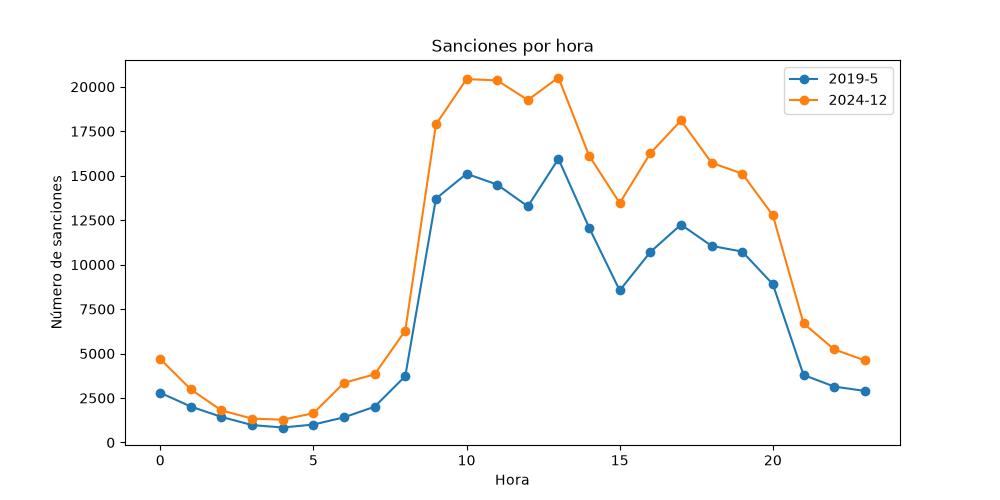

In [57]:
multas.fines_hour("evolucion_multas.png")

Image("evolucion_multas.png")

### Año completo

Si no se pasa el mes se añaden todos los meses publicados de ese año. En 2017 solo hay datos desde junio. Tarda un poco porque descarga 7 ficheros.

In [58]:
multas_2017 = MadridFines("multas", 7)
multas_2017.add(2017)

multas_2017.loaded

[(6, 2017),
 (7, 2017),
 (8, 2017),
 (9, 2017),
 (10, 2017),
 (11, 2017),
 (12, 2017)]

In [59]:
multas_2017.fines_calification()

,CALIFICACION,GRAVE,LEVE,MUY GRAVE
MES,ANIO,,,
6,2017,67448,178729,814
7,2017,70102,164257,740
8,2017,67724,123994,655
9,2017,73765,173823,822
10,2017,76251,171880,893
11,2017,70405,161110,759
12,2017,63513,140466,836


### Borrar la caché

`clean_cache` borra los ficheros descargados.

In [60]:
print(len(os.listdir(multas.cacheurl.cache_dir)))

multas.clean_cache()

print(len(os.listdir(multas.cacheurl.cache_dir)))

9
0
